### Depth Script
---
This script covers the bridge between the Blender exr file and the MASTADON txt file

#### Functions

In [23]:
import OpenEXR
import Imath
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import os

def exr_to_array(filepath: Path, channel: str = "Z"):
    """
    converts the exr file into an np array
    """
    exrfile = OpenEXR.InputFile(filepath.as_posix())
    
    # Read the channel as raw bytes
    raw_bytes = exrfile.channel(channel, Imath.PixelType(Imath.PixelType.FLOAT))
    
    # Convert to NumPy array
    depth_vector = np.frombuffer(raw_bytes, dtype=np.float32)
    
    # Get dimensions from header
    header = exrfile.header()
    display_window = header['displayWindow']
    width = display_window.max.x - display_window.min.x + 1
    height = display_window.max.y - display_window.min.y + 1
    
    # Reshape to 2D
    depth_map = depth_vector.reshape((height, width))
    return depth_map

def save_heightmap_txt(filename, depth_map, min_x, dx, min_y, dy):
    """
    converts the np array to a txt heightmap meant for MASTADON
    """
    depth_for_export = depth_map
    rows, cols = depth_for_export.shape     # now rows = Nx, cols = Ny
    vectorized = depth_for_export.flatten(order='C')

    with open(filename, 'w') as f:
        # Header lines
        f.write(f"{cols} {rows}\n")
        f.write(f"{min_x:.6f} {dx:.6f}\n")
        f.write(f"{min_y:.6f} {dy:.6f}\n")

        # Data lines: one value per line
        for val in vectorized:
            f.write(f"{val:.6f}\n")

def read_height_map_txt(filename):
    """
    Read height map data from a text file.
    
    Parameters:
    -----------
    filename : str
        Path to the text file
        
    Returns:
    --------
    x : numpy.ndarray
        X-axis coordinates
    y : numpy.ndarray
        Y-axis coordinates
    H : numpy.ndarray
        Height map data
    """
    with open(filename, 'r') as fid:
        # Read first line and parse nx, ny
        s = fid.readline().strip()
        num = [int(val) for val in s.split()]
        nx = num[0]
        ny = num[1]
        
        # Read second line and parse x values
        s = fid.readline().strip()
        xvals = [float(val) for val in s.split()]
        
        # Read third line and parse y values
        s = fid.readline().strip()
        yvals = [float(val) for val in s.split()]
        
        xmin = xvals[0]
        dx = xvals[1]
        ymin = yvals[0]
        dy = yvals[1]
        
        xmax = xmin + dx * nx
        ymax = ymin + dy * ny
        
        # Read remaining data
        remaining_text = fid.read()
        data = [float(val) for val in remaining_text.split()]
    
    # Reshape data to match MATLAB's column-major ordering
    data = np.array(data)
    H = data.reshape((nx, ny), order='F')
    
    # Generate coordinate arrays
    x = np.arange(xmin + dx, xmax + dx, dx)
    y = np.arange(ymin + dy, ymax + dy, dy)
    
    return x, y, H


def read_height_map_hdf5(filename):
    """
    Read height map data from an HDF5 file.
    
    Parameters:
    -----------
    filename : str
        Path to the HDF5 file
        
    Returns:
    --------
    x : numpy.ndarray
        X-axis coordinates
    y : numpy.ndarray
        Y-axis coordinates
    H : numpy.ndarray
        Height map data
    """
    # Placeholder - implement HDF5 reading as needed
    raise NotImplementedError("HDF5 reading not yet implemented")


def read_height_map(filename):
    """
    Read height map from file (supports .txt and .hdf5/.h5 formats).
    
    Parameters:
    -----------
    filename : str
        Path to the file
        
    Returns:
    --------
    x : numpy.ndarray
        X-axis coordinates
    y : numpy.ndarray
        Y-axis coordinates
    H : numpy.ndarray
        Height map data
    """
    _, ext = os.path.splitext(filename)
    ext_lower = ext.lower()
    
    if ext_lower == ".txt":
        x, y, H = read_height_map_txt(filename)
    elif ext_lower == ".hdf5" or ext_lower == ".h5":
        x, y, H = read_height_map_hdf5(filename)
    else:
        raise ValueError("Unrecognized file format")
    
    return x, y, H


def view_height_map(filename):
    """
    Visualize height map data from file.
    
    Parameters:
    -----------
    filename : str
        Path to the height map file
    """
    x, y, H = read_height_map(filename)
    
    plt.figure()
    H_transposed = H.T
    # H_flipped = np.flipud(H_transposed)
    
    plt.imshow(H_transposed, extent=[x[0], x[-1], y[0], y[-1]], origin='lower', cmap='RdBu', aspect="auto")
    
    plt.title("Bathymetry (from txt file)")
    plt.xlabel('X (m)')
    plt.ylabel('Y (m)')
    plt.colorbar()
    plt.xlim([x[0], x[-1]])
    plt.ylim([y[0], y[-1]])
    
    plt.show()

#### EXR to Depth Map

Available channels: ['Value.V']


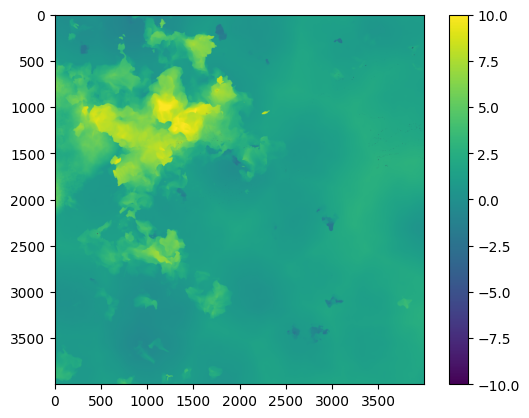

In [ ]:
# just set the filepath and run this
exr_filepath = "PUT FILEPATH HERE"

# this part just informs you of the channel names in case "Value.V" isn't the depth channel
with OpenEXR.File(exr_filepath) as infile:
    channel_dict = infile.channels()  # Returns a dict
    print("Available channels:", list(channel_dict.keys()))

# get the depth map
depth_map = exr_to_array(Path(exr_filepath), channel="Value.V")

# visualize the depth map
plt.imshow(depth_map, cmap='viridis')
plt.colorbar()
plt.show()

#### Depth Map to TXT

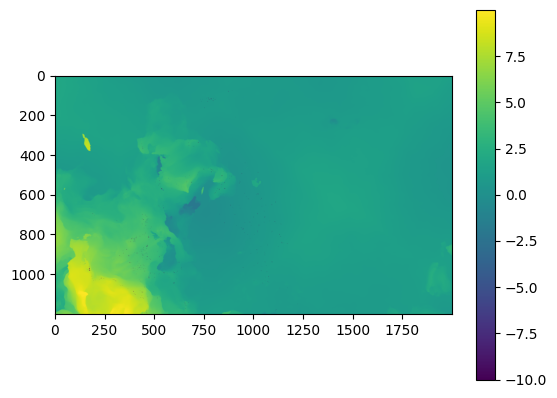

In [19]:
# only adjust these three values; if you do adjust them then fix the config file as well
patch_width_meters = 50
patch_height_meters = 30
patch_resolution = 0.025

patch_width_px = int(patch_width_meters/patch_resolution)
patch_height_px = int(patch_height_meters/patch_resolution)

output_height, output_width = depth_map.shape

random_patch_x = np.random.randint(0, output_width-patch_width_px)
random_patch_y = np.random.randint(0, output_height-patch_height_px)

depth_patch = depth_map[random_patch_x:random_patch_x+patch_width_px, random_patch_y:random_patch_y+patch_height_px].T

# visualize the depth map
plt.imshow(np.flipud(depth_patch), cmap='viridis')
plt.colorbar()
plt.show()

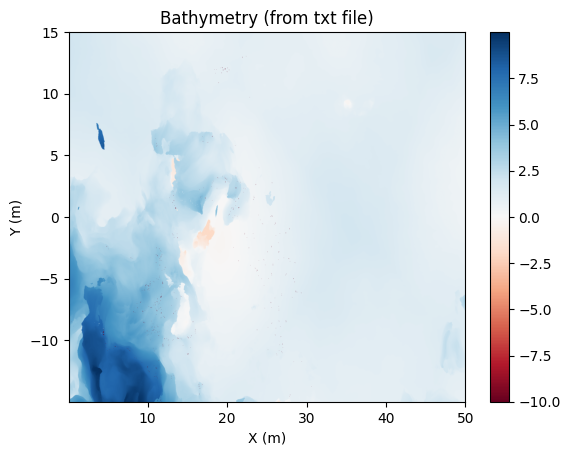

In [24]:
min_x = 0    # Start x position of the patch in meters
min_y = -(patch_height_meters//2)    # Start y position of the patch in meters
dx = dy = patch_resolution

txt_filename = "depth.txt"

save_heightmap_txt(txt_filename, depth_patch, min_x, dx, min_y, dy)
view_height_map(txt_filename)